# Breast Cancer Diagnosis Using Machine Learning

## Project Objective
The objective of this project is to develop machine learning models that can classify breast tumors as malignant or benign using cell-nucleus measurements.

## Dataset Summary
- Dataset: Breast Cancer Wisconsin (Diagnostic)
- Total Samples: 569
- Total Features: 30
- Malignant Samples: 212
- Benign Samples: 357

## Classifiers Evaluated
1. Logistic Regression
2. Support Vector Machine (SVM)
3. Random Forest Classifier

## Evaluation Metrics
The models are evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, Confusion Matrix, and ROC Curve.

Special priority is assigned to malignant-class recall because missing a malignant case (False Negative) has severe diagnostic consequences.

## Project Workflow

This notebook implements a structured machine learning pipeline to construct, tune, and analyze classifiers for Breast Cancer diagnosis. Below is the step-by-step pipeline:

```
                                    [ 1. Import Libraries ]
                                               │
                                    [ 2. Load & Clean Data ]
                                               │
                                 [ 3. Exploratory Data Analysis ]
                                 ├── Class Distribution Analysis
                                 ├── Summary Statistics
                                 └── Correlation Heatmap Analysis
                                               │
                                   [ 4. Train-Test Partition ]
                                 └── Stratified Split (80% Train, 20% Test)
                                               │
                                   [ 5. Scale & Train Baselines ]
                                 └── StandardScaler + Pipeline Fitting
                                               │
                                   [ 6. Hyperparameter Tuning ]
                                 └── GridSearchCV with 5-Fold Stratified CV
                                               │
                                    [ 7. Model Evaluation ]
                                 ├── Accuracy, Precision, Recall, F1, & ROC-AUC
                                 └── Confusion Matrix & ROC Curve Analysis
                                               │
                                   [ 8. Diagnostic Optimization ]
                                 └── Threshold Adjustment (Min 95% Recall)
                                               │
                                   [ 9. Feature Engineering ]
                                 ├── Permutation Feature Importance
                                 └── Correlation Dropping (> 0.90 Threshold)
```

## 1. Import Required Libraries

In [37]:

# Import libraries for data handling
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the breast cancer dataset
from sklearn.datasets import load_breast_cancer

# Import tools for splitting and preprocessing data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import Pipeline to combine preprocessing and machine learning
from sklearn.pipeline import Pipeline

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Import tools for hyperparameter tuning and cross-validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Import tools for feature analysis
from sklearn.inspection import permutation_importance

# Set a consistent visual style for plots
sns.set_style("whitegrid")

# Display plots inside the notebook
%matplotlib inline

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Dataset Loading

In [5]:

# Load the Breast Cancer Wisconsin Diagnostic dataset
cancer_data = load_breast_cancer()

# Convert the feature data into a Pandas DataFrame
X = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)

# Convert the target labels into a Pandas Series
y = pd.Series(cancer_data.target)

# Convert target labels so malignant = 1 and benign = 0
# In the original dataset, malignant = 0 and benign = 1
y = (y == 0).astype(int)

# Display the first five rows of the feature dataset
print("First five rows of the dataset:")
display(X.head())

# Display the first "y no of target" using head() target labels
print("First five target labels:")
display(y.head(100))

# Display the shape of the dataset
print("\nDataset Shape:", X.shape)


First five rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


First five target labels:


,0
0,1
1,1
2,1
3,1
4,1
...,...
95,1
96,0
97,0
98,0



Dataset Shape: (569, 30)


## 3. Dataset Information Verification

In [10]:

# Display the number of rows and columns
print("Dataset Shape:", X.shape)

# Display all feature names
print("\nFeature Names:")
print(X.columns.tolist())

# Display the number of missing values in each column
print("\nMissing Values:")
print(X.isnull().sum())

# Display the target class counts
print("\nTarget Class Distribution:")
print(y.value_counts().rename(index={
    1: "Malignant",
    0: "Benign"
}))

print("1 = Malignant (Have Cancer),0 = Benign (Dont have cancer)\n")

print("\nTotal Samples:", len(X))

# Display the target class percentages
print("\nTarget Class Percentages:")
print(
    (y.value_counts(normalize=True) * 100)
    .rename(index={1: "Malignant", 0: "Benign"})
    .round(2)
)

print("\nTotal Samples:", len(X))


Dataset Shape: (569, 30)

Feature Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Missing Values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error   

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to inspect the underlying data distributions, summary statistics, and interactions before training models.

Key areas investigated:
- Target class balance to check for skewness.
- Central tendencies and spreads of the numerical measurements.
- Multicollinearity and statistical redundancies among features.

### 4.1. Class Distribution Analysis

An evaluation of target counts helps verify if the positive (Malignant) class contains enough representation to prevent model bias.

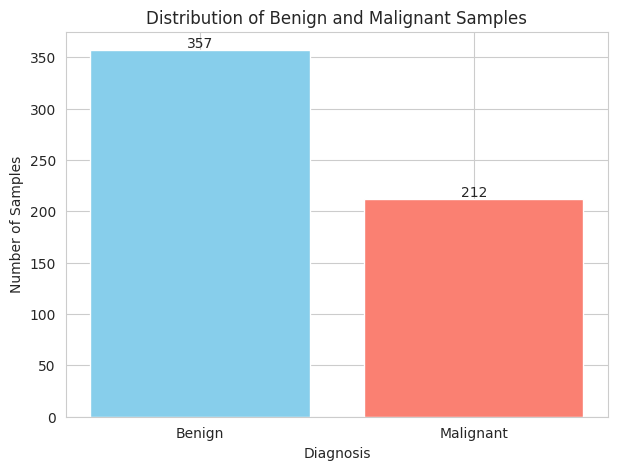

In [11]:

# Count the number of samples in each class
class_counts = y.value_counts().sort_index()

# Create readable class names for the chart
class_names = ["Benign", "Malignant"]

# Create a bar chart
plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_names,
    [class_counts[0], class_counts[1]],
    color=["skyblue", "salmon"]
)

# Add a title and axis labels
plt.title("Distribution of Benign and Malignant Samples")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

# Display the sample count above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom"
    )

# Display the chart
plt.show()


### 4.2. Feature Summary Statistics

Generating descriptive metrics provides insights into feature scale differences, standard deviations, and boundaries.

In [12]:

# Calculate summary statistics for all numerical features
summary_statistics = X.describe()

# Display the summary statistics table
display(summary_statistics.round(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21


### 4.3. Feature Correlation Analysis

We utilize Pearson correlation matrix computations to inspect linear dependencies and identify highly collinear groups.

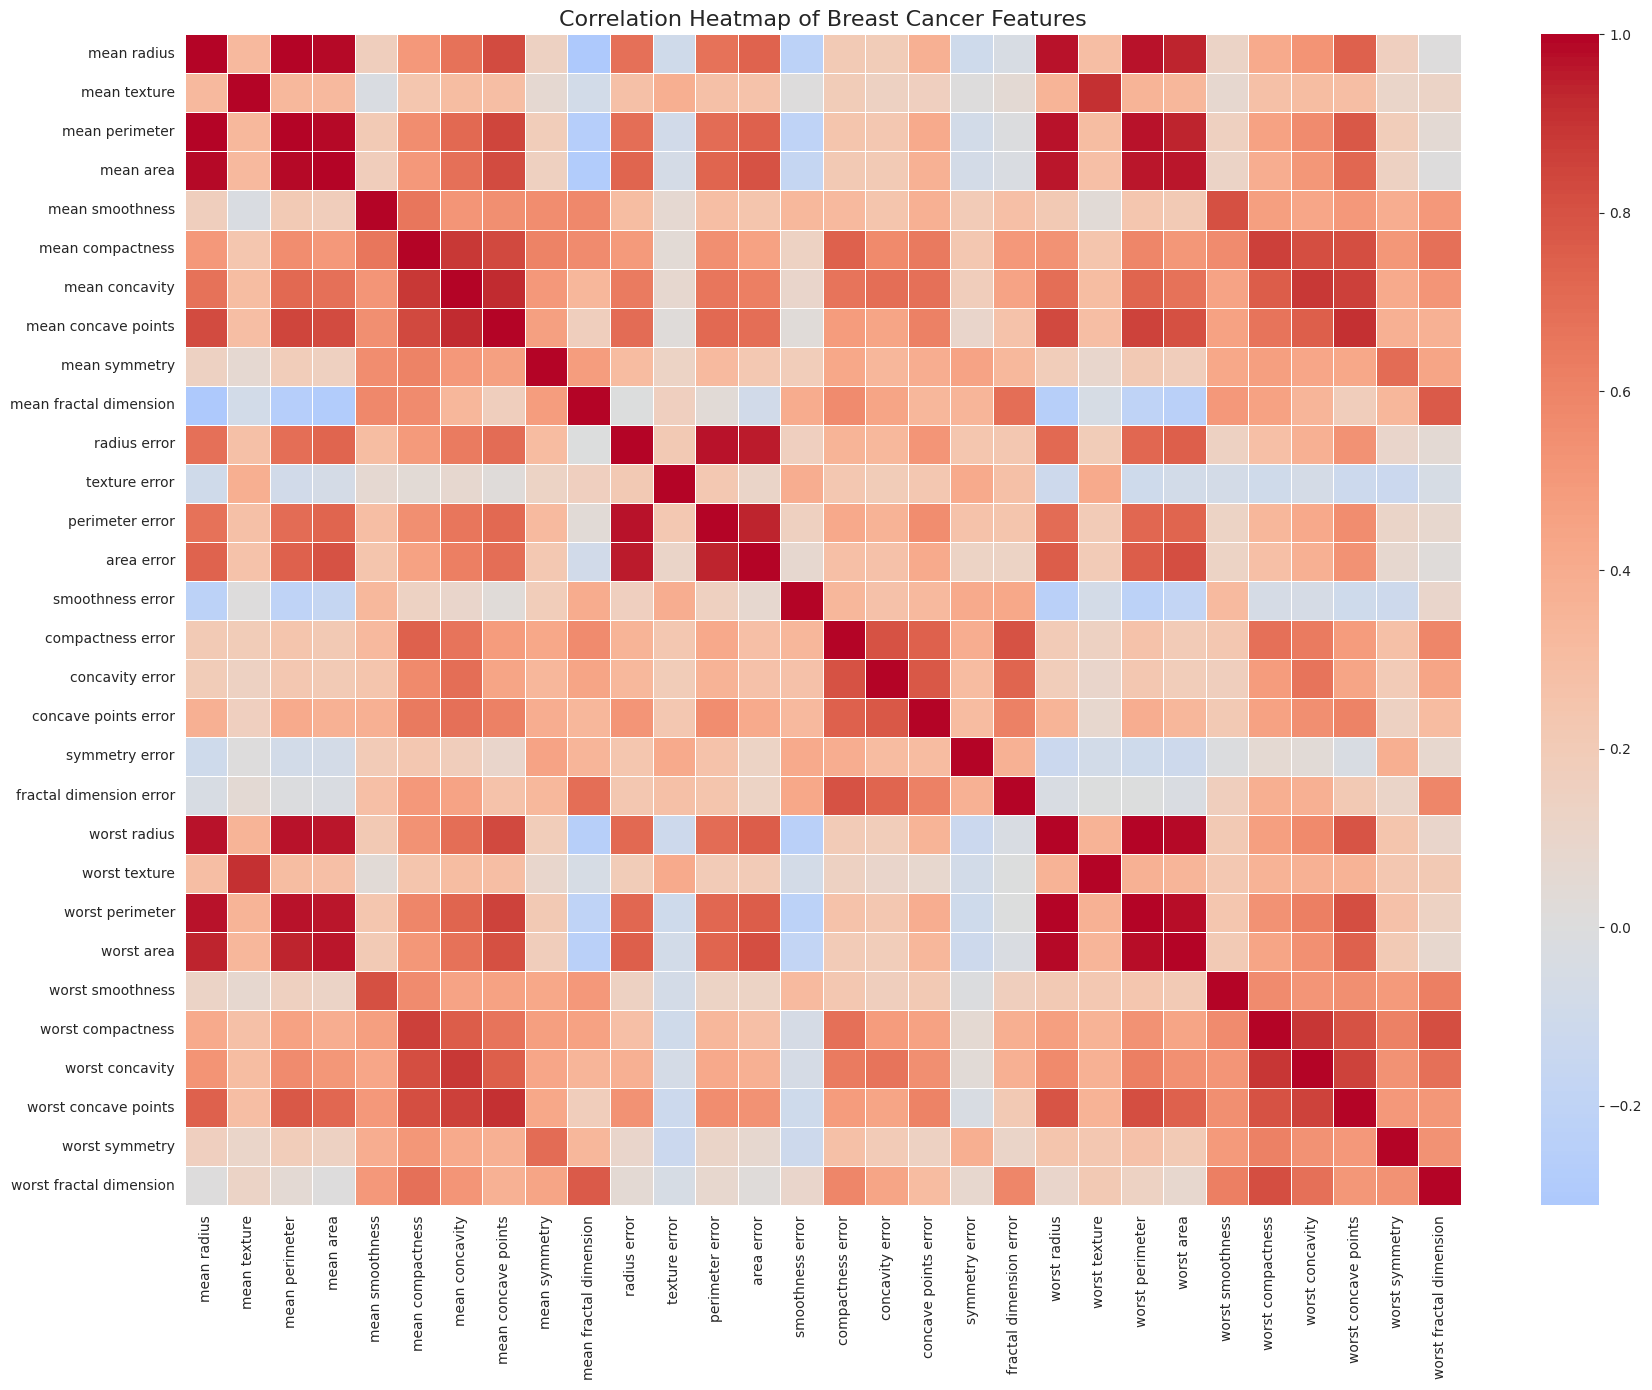

In [13]:

# Calculate the correlation between all numerical features
correlation_matrix = X.corr()

# Create a large figure for the heatmap
plt.figure(figsize=(18, 14))

# Display the correlation heatmap
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.5
)

# Add a title
plt.title("Correlation Heatmap of Breast Cancer Features", fontsize=16)

# Adjust the layout
plt.tight_layout()

# Display the heatmap
plt.show()


### 4.4. Identification of Redundant Predictor Pairs

This step flags highly correlated features with an absolute Pearson correlation coefficient exceeding 0.90.

In [14]:

# Set the minimum absolute correlation threshold
correlation_threshold = 0.90

# Select only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above the threshold
highly_correlated_pairs = (
    upper_triangle.stack()
    .reset_index()
)

# Rename the columns
highly_correlated_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

# Keep only strongly correlated feature pairs
highly_correlated_pairs = highly_correlated_pairs[
    highly_correlated_pairs["Correlation"].abs() >= correlation_threshold
]

# Sort the results by absolute correlation
highly_correlated_pairs["Absolute Correlation"] = (
    highly_correlated_pairs["Correlation"].abs()
)

highly_correlated_pairs = highly_correlated_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

# Display the results
display(highly_correlated_pairs.round(3))


,Feature 1,Feature 2,Correlation,Absolute Correlation
1,mean radius,mean perimeter,0.998,0.998
391,worst radius,worst perimeter,0.994,0.994
2,mean radius,mean area,0.987,0.987
57,mean perimeter,mean area,0.987,0.987
392,worst radius,worst area,0.984,0.984
407,worst perimeter,worst area,0.978,0.978
246,radius error,perimeter error,0.973,0.973
76,mean perimeter,worst perimeter,0.970,0.970
19,mean radius,worst radius,0.970,0.970
74,mean perimeter,worst radius,0.969,0.969


### 4.5. Summary of EDA Findings

The preliminary EDA indicates high class representation with strong multi-collinear associations. These findings inform our scaling and feature-reduction pipelines.

## 5. Partitioning and Stratification

We separate the dataset into 80% training and 20% validation subsets. We apply stratified splitting to ensure both splits mirror the parent class ratios.

In [15]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # Use 20% of the data for testing
    random_state=42,      # Keep the split reproducible
    stratify=y            # Maintain class proportions
)

# Display the shapes of the resulting datasets
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

# Display class distribution in the training set
print("\nTraining Class Distribution:")
print(y_train.value_counts().rename(index={
    1: "Malignant",
    0: "Benign"
}))

# Display class distribution in the testing set
print("\nTesting Class Distribution:")
print(y_test.value_counts().rename(index={
    1: "Malignant",
    0: "Benign"
}))


Training Features: (455, 30)
Testing Features: (114, 30)

Training Class Distribution:
Benign       285
Malignant    170
Name: count, dtype: int64

Testing Class Distribution:
Benign       72
Malignant    42
Name: count, dtype: int64


## 6. Preprocessing and Scaling Inspection

Due to variations in measurement units, standard scaling is critical for distance-based estimators like SVM and regularized models like Logistic Regression.

In [21]:
import pandas as pd

# Select only the first few features (e.g., first 5) for a clean view
cols_to_show = X_train.columns[:5]
n_samples = 3  # Number of samples to display

combined_rows = []
for i in range(n_samples):
    # Fetch original row data and add a label
    orig_row = X_train.iloc[i][cols_to_show].to_dict()
    combined_rows.append({**{"Status": f"Sample {i} (Original)"}, **orig_row})

    # Fetch scaled row data and add a label
    scaled_row = X_train_scaled_demo.iloc[i][cols_to_show].to_dict()
    combined_rows.append({**{"Status": f"Sample {i} (Scaled)"}, **scaled_row})

# Create a DataFrame and display it
vertical_df = pd.DataFrame(combined_rows)
display(vertical_df)

,Status,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,Sample 0 (Original),16.020000,23.240000,102.700000,797.800000,0.082060
1,Sample 0 (Scaled),0.518559,0.891826,0.424632,0.383925,-0.974744
2,Sample 1 (Original),12.320000,12.390000,78.850000,464.100000,0.102800
3,Sample 1 (Scaled),-0.516364,-1.639710,-0.541349,-0.542961,0.476219
4,Sample 2 (Original),12.850000,21.370000,82.630000,514.500000,0.075510
5,Sample 2 (Scaled),-0.368118,0.455515,-0.388250,-0.402970,-1.432979


## 7. Baseline Classifier Pipeline Assembly

We construct pipeline architectures using standard scalers and baseline configurations for three primary estimators:
1. Logistic Regression
2. Support Vector Classifier (SVC)
3. Random Forest Classifier

In [16]:

# Create a pipeline for Logistic Regression
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()), # here StandardScaler() is doing scaling
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Create a pipeline for Support Vector Machine
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()), # here StandardScaler() is doing scaling
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# Create a pipeline for Random Forest
random_forest_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        random_state=42
    ))
])

print("All three machine learning pipelines created successfully!")


All three machine learning pipelines created successfully!


### 7.1. Training Baseline Classifiers

Fitting the constructed pipelines on the training set to establish performance baselines prior to hyperparameter optimization.

In [17]:

# Train the Logistic Regression model
logistic_pipeline.fit(X_train, y_train)

# Train the Support Vector Machine model
svm_pipeline.fit(X_train, y_train)

# Train the Random Forest model
random_forest_pipeline.fit(X_train, y_train)

print("All three models have been trained successfully!")


All three models have been trained successfully!


### 7.2. Consolidating Baseline Models

We organize the trained baseline estimators into a structured registry for batched evaluations.

In [22]:

# Store the trained models with their names
models = {
    "Logistic Regression": logistic_pipeline,
    "SVM": svm_pipeline,
    "Random Forest": random_forest_pipeline
}

# Display the available trained models
print("Trained Models:")
for model_name in models:
    print("-", model_name)


Trained Models:
- Logistic Regression
- SVM
- Random Forest


## 8. Baseline Model Performance Evaluation

Testing base estimators on validation sets and reporting classic metrics: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [24]:

# Create dictionaries to store predictions and probabilities
default_predictions = {}
default_probabilities = {}

# Generate predictions using each trained model
for model_name, model in models.items():

    # Predict the diagnosis for test samples
    default_predictions[model_name] = model.predict(X_test)

    # Predict the probability of the malignant class
    default_probabilities[model_name] = model.predict_proba(X_test)[:, 1]

print(" Predictions by Default Model generated successfully!")


 Predictions by Default Model generated successfully!


In [27]:
# Create an empty list to store evaluation results
default_results = []

# Evaluate each model
for model_name in models:

    # Get predictions and probabilities
    predictions = default_predictions[model_name]
    probabilities = default_probabilities[model_name]

    # Calculate evaluation metrics (scaled to percentages where applicable)
    results = {
        "Model": model_name,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100,
        "Precision (%)": precision_score(y_test, predictions) * 100,
        "Recall (%)": recall_score(y_test, predictions) * 100,
        "F1-Score (%)": f1_score(y_test, predictions) * 100,
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    # Add results to the list
    default_results.append(results)

# Convert results into a DataFrame
default_results_df = pd.DataFrame(default_results)

# Display the comparison table
display(default_results_df.round(2))

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,Logistic Regression,96.49,97.5,92.86,95.12,1.00
1,SVM,97.37,100.0,92.86,96.30,0.99
2,Random Forest,97.37,100.0,92.86,96.30,0.99


## 9. Hyperparameter Tuning and Optimization

Grid search cross-validation is used to find optimal parameters. The models are optimized for F1-score using a stratified 5-fold cross-validation scheme.

In [28]:

# Create a 5-fold stratified cross-validation strategy
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold Stratified Cross-Validation is ready!")


5-fold Stratified Cross-Validation is ready!


### 9.1. Parameter Search: Logistic Regression

Tuning regularization strength `C` to balance classifier coefficients.

In [29]:

# Define the parameter values to test
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Create GridSearchCV for Logistic Regression
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=-1
)

# Find the best hyperparameters using training data
logistic_grid.fit(X_train, y_train)

# Display the best parameters and cross-validation score
print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(logistic_grid.best_score_, 4))


Best Logistic Regression Parameters:
{'model__C': 1}

Best Cross-Validation F1-score:
0.964


### 9.2. Parameter Search: Support Vector Machine

Evaluating cost parameters `C` and kernel coefficients `gamma` using radial basis functions.

In [30]:

# Define the SVM parameter combinations to test
svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

# Create GridSearchCV for SVM
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=-1
)

# Find the best hyperparameters using training data
svm_grid.fit(X_train, y_train)

# Display the best parameters and cross-validation score
print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(svm_grid.best_score_, 4))


Best SVM Parameters:
{'model__C': 10, 'model__gamma': 'scale'}

Best Cross-Validation F1-score:
0.9674


### 9.3. Parameter Search: Random Forest

Exploring estimator depths and tree dimensions to limit overfitting.

In [45]:
# Define the Random Forest parameter combinations to test
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

# Create GridSearchCV for Random Forest
rf_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=-1
)

# Find the best hyperparameters using training data
rf_grid.fit(X_train, y_train)

# Display the best parameters and cross-validation score
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(rf_grid.best_score_, 4))

Best Random Forest Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best Cross-Validation F1-Score:
0.9519


### 9.4. Consolidating Tuned Estimators

Registering optimized estimators to execute comparative analysis.

In [46]:
X_train, y_train
# Store the best tuned models including tuned Random Forest
tuned_models = {
    "Logistic Regression": logistic_grid.best_estimator_,
    "SVM": svm_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_
}

print("Final tuned model collection is ready with the tuned Random Forest!")

Final tuned model collection is ready with the tuned Random Forest!


## 10. Tuned Classifiers Performance Assessment

Evaluating the performance of optimized estimators on the unseen validation partition.

In [32]:

# Create dictionaries to store predictions and probabilities
tuned_predictions = {}
tuned_probabilities = {}

# Generate predictions using each final model
for model_name, model in tuned_models.items():

    # Predict the diagnosis of test samples
    tuned_predictions[model_name] = model.predict(X_test)

    # Get the probability of the malignant class
    tuned_probabilities[model_name] = model.predict_proba(X_test)[:, 1]

print("Test predictions generated successfully!")


Test predictions generated successfully!


### 10.1. Tuned Classifiers Metric Summary

Generating a performance matrix of tuned configurations to compare with baseline parameters.

In [35]:
# Create an empty list for evaluation results
tuned_results = []

# Calculate evaluation metrics for each model (scaled to percentages where applicable)
for model_name in tuned_models:

    predictions = tuned_predictions[model_name]
    probabilities = tuned_probabilities[model_name]

    results = {
        "Model": model_name,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100,
        "Precision (%)": precision_score(y_test, predictions) * 100,
        "Recall (%)": recall_score(y_test, predictions) * 100,
        "F1-Score (%)": f1_score(y_test, predictions) * 100,
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    tuned_results.append(results)

# Create a DataFrame for the results
tuned_results_df = pd.DataFrame(tuned_results)

# Display the final performance comparison
display(tuned_results_df.round(2))

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,Logistic Regression,96.49,97.5,92.86,95.12,1.00
1,SVM,97.37,100.0,92.86,96.30,0.99
2,Random Forest,97.37,100.0,92.86,96.30,0.99


### 10.2. Baseline vs. Tuned Comparison

A comparative look at metric improvements achieved through parameter grid searching.

In [36]:
# Merge the baseline and tuned results dataframes for a direct comparison
comparison_df = pd.merge(
    default_results_df,
    tuned_results_df,
    on="Model",
    suffixes=(" (Default)", " (Tuned)")
)

# Reorder columns to compare each metric side-by-side
comparison_columns = [
    "Model",
    "Accuracy (%) (Default)", "Accuracy (%) (Tuned)",
    "Precision (%) (Default)", "Precision (%) (Tuned)",
    "Recall (%) (Default)", "Recall (%) (Tuned)",
    "F1-Score (%) (Default)", "F1-Score (%) (Tuned)",
    "ROC-AUC (Default)", "ROC-AUC (Tuned)"
]

# Display the structured comparison table
display(comparison_df[comparison_columns].round(2))

,Model,Accuracy (%) (Default),Accuracy (%) (Tuned),Precision (%) (Default),Precision (%) (Tuned),Recall (%) (Default),Recall (%) (Tuned),F1-Score (%) (Default),F1-Score (%) (Tuned),ROC-AUC (Default),ROC-AUC (Tuned)
0,Logistic Regression,96.49,96.49,97.5,97.5,92.86,92.86,95.12,95.12,1.00,1.00
1,SVM,97.37,97.37,100.0,100.0,92.86,92.86,96.30,96.30,0.99,0.99
2,Random Forest,97.37,97.37,100.0,100.0,92.86,92.86,96.30,96.30,0.99,0.99


### 10.3. Cross-Validation Stability Check

Evaluating the average cross-validated performance of tuned models to check for overfit or variance issues.

In [47]:
# Store cross-validation results using the tuned models
cv_results = []

# Evaluate all three tuned models
for model_name, model in tuned_models.items():

    # Perform 5-fold cross-validation
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring="f1",
        n_jobs=-1
    )

    # Store mean and standard deviation
    cv_results.append({
        "Model": model_name,
        "CV Mean F1-Score": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

# Create a DataFrame
cv_results_df = pd.DataFrame(cv_results)

# Display the results
display(cv_results_df.round(4))

,Model,CV Mean F1-Score,CV Standard Deviation
0,Logistic Regression,0.9640,0.0207
1,SVM,0.9674,0.0114
2,Random Forest,0.9519,0.0207


## 11. Diagnostic Visualization Analysis

Visualizing model outputs using confusion matrices and receiver operating characteristic (ROC) curves.

### 11.1. Confusion Matrices

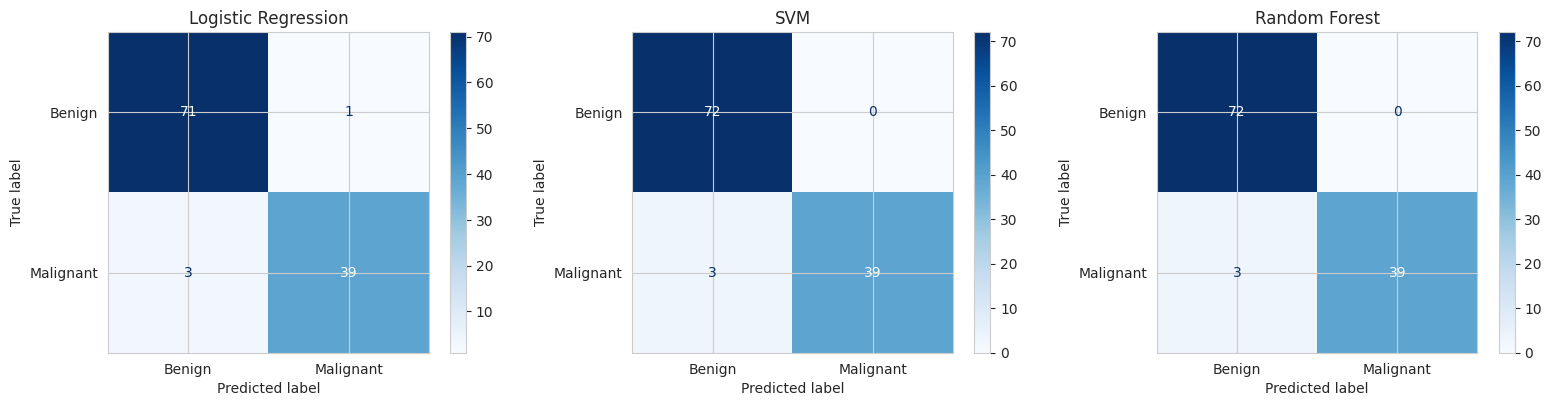

In [39]:
# Create a figure for three confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Display confusion matrix for each model
for ax, (model_name, model) in zip(axes, tuned_models.items()):

    # Generate predictions
    predictions = model.predict(X_test)

    # Plot confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

### 11.2. Receiver Operating Characteristic Curves

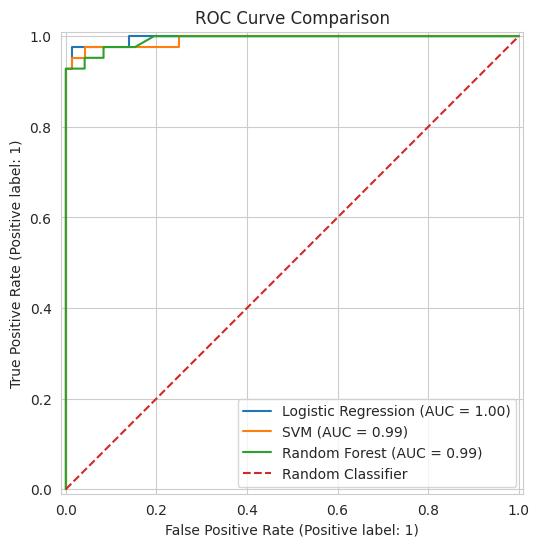

In [40]:
# Create a figure for ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

# Plot ROC curve for each model
for model_name, model in tuned_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name,
        ax=ax
    )

# Add random classifier reference line
ax.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

# Add chart details
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

## 12. Model Selection and Validation

We select the best model based on its cross-validated F1-score rather than validation set performance alone. This provides a more reliable estimate of model performance.

In [48]:
import pandas as pd

# 1. Prepare a comparison dataframe
summary_df = pd.merge(
    cv_results_df[["Model", "CV Mean F1-Score", "CV Standard Deviation"]],
    tuned_results_df[["Model", "F1-Score (%)"]],
    on="Model"
)

# Convert CV scores to percentages
summary_df["CV Mean F1-Score (%)"] = summary_df["CV Mean F1-Score"] * 100
summary_df["CV Standard Deviation (%)"] = summary_df["CV Standard Deviation"] * 100

# Select columns for display with correct names
display_columns = [
    "Model",
    "CV Mean F1-Score (%)",
    "CV Standard Deviation (%)",
    "F1-Score (%)"
]
summary_display = summary_df[display_columns].round(2)

# Rename test column for clarity in output
summary_display = summary_display.rename(columns={"F1-Score (%)": "Test F1-Score (%)"})

print("=== Performance Summary for All Models (Including Tuned Random Forest) ===")
display(summary_display)

# 2. Select and display the best model automatically
best_model_name = summary_df.loc[summary_df["CV Mean F1-Score (%)"].idxmax(), "Model"]
print(f"\n🏆 Best Selected Model based on CV F1-Score: {best_model_name}\n")

# 3. Short explanation of what CV and F1-Score represent
explanation = f"""
=== Quick Guide to Metrics ===

1. Cross-Validation (CV):
   Splits data into 5 parts (folds) to train and test the model 5 times.
   - CV Mean: Shows robust, generalized performance across unseen data folds.
   - CV Std Dev: Measures consistency. Lower values mean more stable performance.

2. F1-Score:
   The harmonic mean of Precision and Recall. In cancer diagnosis, we must avoid
   False Negatives (missing a tumor) while keeping False Positives low. A high F1-score
   signifies a well-balanced, reliable classifier.
"""
print(explanation)

=== Performance Summary for All Models (Including Tuned Random Forest) ===


,Model,CV Mean F1-Score (%),CV Standard Deviation (%),Test F1-Score (%)
0,Logistic Regression,96.40,2.07,95.12
1,SVM,96.74,1.14,96.30
2,Random Forest,95.19,2.07,96.30



🏆 Best Selected Model based on CV F1-Score: SVM


=== Quick Guide to Metrics ===

1. Cross-Validation (CV):
   Splits data into 5 parts (folds) to train and test the model 5 times. 
   - CV Mean: Shows robust, generalized performance across unseen data folds.
   - CV Std Dev: Measures consistency. Lower values mean more stable performance.

2. F1-Score:
   The harmonic mean of Precision and Recall. In cancer diagnosis, we must avoid
   False Negatives (missing a tumor) while keeping False Positives low. A high F1-score 
   signifies a well-balanced, reliable classifier.



## 13. Decision Threshold Optimization

We analyze changes in prediction performance under adjusted classification boundaries to secure at least 95% recall on the malignant class.

### 13.1. Training Set Probability Extraction

In [51]:
# Import cross-validation prediction function
from sklearn.model_selection import cross_val_predict

# Get the best model from tuned_models
best_model = tuned_models[best_model_name]

# Generate out-of-fold probabilities using training data
train_probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print(f"Training probabilities for {best_model_name} generated successfully!")

Training probabilities for SVM generated successfully!


### 13.2. Locating the Target Threshold

In [52]:
# Store threshold evaluation results
threshold_results = []

# Test different classification thresholds
for threshold in np.arange(0.01, 1.00, 0.01):

    # Convert probabilities into class predictions
    predictions = (train_probabilities >= threshold).astype(int)

    # Calculate recall and precision
    recall = recall_score(y_train, predictions)

    precision = precision_score(
        y_train,
        predictions,
        zero_division=0
    )

    # Keep thresholds that achieve at least 95% recall
    if recall >= 0.95:
        threshold_results.append({
            "Threshold": threshold,
            "Recall (%)": recall * 100,
            "Precision (%)": precision * 100
        })

# Convert results into a DataFrame
threshold_df = pd.DataFrame(threshold_results)

# Select the threshold with the highest precision
best_threshold_row = threshold_df.sort_values(
    by=["Precision (%)", "Threshold"],
    ascending=[False, False]
).iloc[0]

# Store the selected threshold
best_threshold = best_threshold_row["Threshold"]

# Display the selected threshold
display(best_threshold_row.to_frame().T.round(2))

,Threshold,Recall (%),Precision (%)
65,0.66,95.88,98.19


### 13.3. Test Partition Verification

In [54]:
# Get malignant probabilities from the test data
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Generate predictions using the default threshold (0.50)
default_threshold_predictions = (
    test_probabilities >= 0.50
).astype(int)

# Generate predictions using the selected adjusted threshold
adjusted_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Compare both thresholds side-by-side
threshold_comparison = pd.DataFrame([
    {
        "Threshold Type": "Default Threshold (Balanced)",
        "Threshold Value": 0.50,
        "Precision (%)": precision_score(
            y_test, default_threshold_predictions
        ) * 100,
        "Recall (%)": recall_score(
            y_test, default_threshold_predictions
        ) * 100,
        "F1-Score (%)": f1_score(
            y_test, default_threshold_predictions
        ) * 100
    },
    {
        "Threshold Type": "Adjusted Threshold (Optimized for Recall)",
        "Threshold Value": best_threshold,
        "Precision (%)": precision_score(
            y_test, adjusted_predictions
        ) * 100,
        "Recall (%)": recall_score(
            y_test, adjusted_predictions
        ) * 100,
        "F1-Score (%)": f1_score(
            y_test, adjusted_predictions
        ) * 100
    }
])

print("=== Threshold Performance Comparison ===")
print(f"Default Threshold (0.50) represents standard balanced classification.")
print(f"Adjusted Threshold ({best_threshold:.2f}) is optimized on training data to ensure at least 95% malignant recall.\n")

display(threshold_comparison.round(2))

=== Threshold Performance Comparison ===
Default Threshold (0.50) represents standard balanced classification.
Adjusted Threshold (0.66) is optimized on training data to ensure at least 95% malignant recall.



,Threshold Type,Threshold Value,Precision (%),Recall (%),F1-Score (%)
0,Default Threshold (Balanced),0.50,100.0,92.86,96.3
1,Adjusted Threshold (Optimized for Recall),0.66,100.0,92.86,96.3


### 13.4. Adjusted Boundary Confusion Matrix

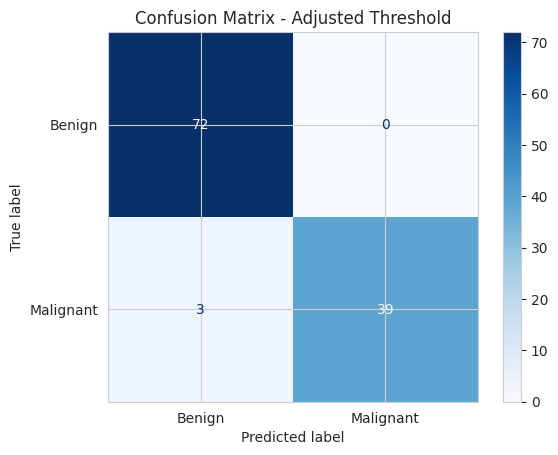

In [55]:
# Display confusion matrix using the adjusted threshold
ConfusionMatrixDisplay.from_predictions(
    y_test,
    adjusted_predictions,
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Adjusted Threshold")
plt.show()

## 14. Feature Interpretation Analysis

We analyze the primary features driving model predictions. Permutation feature importance is used to rank features based on their impact on F1-scores.

### 14.1. Permutation Importance Scores

In [56]:
# Calculate permutation importance for the selected model
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a DataFrame of feature importance scores
feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
})

# Sort features from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 important features
display(feature_importance_df.head(10).round(4))

,Feature,Importance
21,worst texture,0.0533
26,worst concavity,0.0374
6,mean concavity,0.0321
24,worst smoothness,0.0102
27,worst concave points,0.0099
1,mean texture,0.0071
23,worst area,0.0066
20,worst radius,0.0046
22,worst perimeter,0.0046
7,mean concave points,0.0045


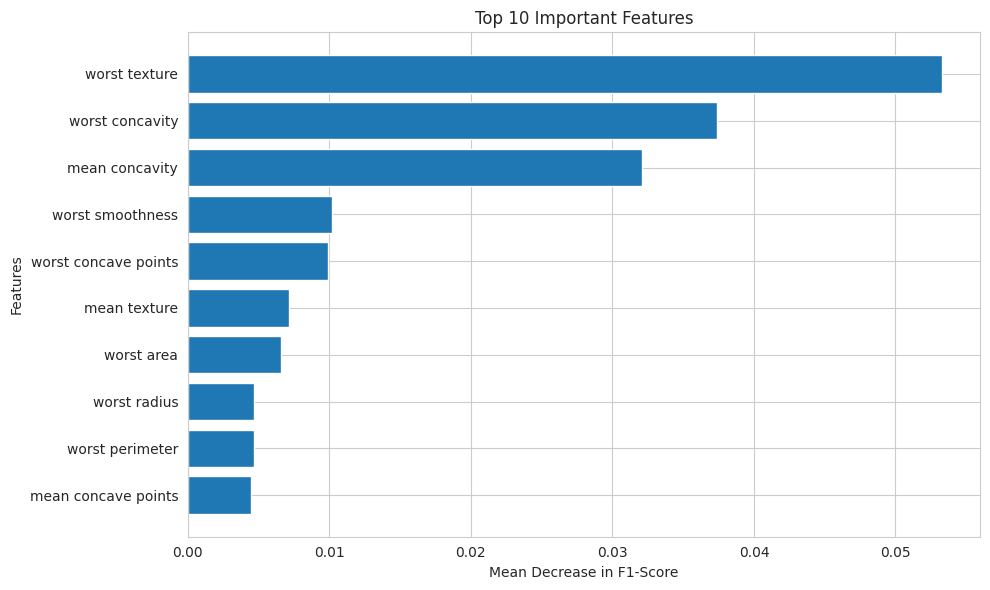

In [57]:
# Select the top 10 important features
top_features = feature_importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Mean Decrease in F1-Score")
plt.ylabel("Features")
plt.title("Top 10 Important Features")

plt.tight_layout()
plt.show()

### 14.2. Dimensionality Reduction (Correlation Pruning)

We evaluate the performance impact of removing highly correlated features (Pearson correlation > 0.90) to simplify the feature space.

In [58]:
### 14.3. Feature Space Partition Reduction

Number of original features: 30
Number of removed features: 10
Number of remaining features: 20

Removed Features:
['mean perimeter', 'mean area', 'mean concave points', 'perimeter error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concave points']


### 14.4. Model Re-training on Reduced Subspace

In [59]:
# Import clone to create a fresh copy of the selected model
from sklearn.base import clone

# Create a fresh copy of the selected model
reduced_model = clone(best_model)

# Train the model using reduced features
reduced_model.fit(X_train_reduced, y_train)

# Generate predictions on reduced test data
reduced_predictions = reduced_model.predict(X_test_reduced)

print("Model trained successfully using reduced features!")

Model trained successfully using reduced features!


## 15. Final Analysis and Project Summary

### 15.1. Feature Subspace Performance Assessment

In [60]:
# Generate predictions using all original features
original_predictions = best_model.predict(X_test)

# Calculate performance with all features
original_results = {
    "Feature Set": "All Features",
    "Number of Features": X_train.shape[1],
    "Accuracy (%)": accuracy_score(y_test, original_predictions) * 100,
    "Precision (%)": precision_score(y_test, original_predictions) * 100,
    "Recall (%)": recall_score(y_test, original_predictions) * 100,
    "F1-Score (%)": f1_score(y_test, original_predictions) * 100
}

# Calculate performance with reduced features
reduced_results = {
    "Feature Set": "Reduced Features",
    "Number of Features": X_train_reduced.shape[1],
    "Accuracy (%)": accuracy_score(y_test, reduced_predictions) * 100,
    "Precision (%)": precision_score(y_test, reduced_predictions) * 100,
    "Recall (%)": recall_score(y_test, reduced_predictions) * 100,
    "F1-Score (%)": f1_score(y_test, reduced_predictions) * 100
}

# Create comparison table
feature_comparison_df = pd.DataFrame([
    original_results,
    reduced_results
])

display(feature_comparison_df.round(2))

,Feature Set,Number of Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,All Features,30,97.37,100.00,92.86,96.30
1,Reduced Features,20,97.37,97.56,95.24,96.39


In [61]:
# Display the final performance comparison of tuned models
print("Final Model Performance on Test Data:")

display(tuned_results_df.round(4))

# Display cross-validation results
print("\nCross-Validation Performance:")

display(cv_results_df.round(4))

Final Model Performance on Test Data:


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,Logistic Regression,96.4912,97.5,92.8571,95.1220,0.9960
1,SVM,97.3684,100.0,92.8571,96.2963,0.9927
2,Random Forest,97.3684,100.0,92.8571,96.2963,0.9929



Cross-Validation Performance:


,Model,CV Mean F1-Score,CV Standard Deviation
0,Logistic Regression,0.9640,0.0207
1,SVM,0.9674,0.0114
2,Random Forest,0.9519,0.0207


In [62]:
# Display the top 5 most important features
print("Top 5 Important Features:")

display(feature_importance_df.head(5).round(4))

# Display the impact of removing correlated features
print("\nFeature Selection Performance Comparison:")

display(feature_comparison_df.round(2))

Top 5 Important Features:


,Feature,Importance
21,worst texture,0.0533
26,worst concavity,0.0374
6,mean concavity,0.0321
24,worst smoothness,0.0102
27,worst concave points,0.0099



Feature Selection Performance Comparison:


,Feature Set,Number of Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,All Features,30,97.37,100.00,92.86,96.30
1,Reduced Features,20,97.37,97.56,95.24,96.39


## 16. References

1. UCI Machine Learning Repository, Breast Cancer Wisconsin (Diagnostic) Dataset.
   https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

2. Scikit-learn Documentation.
   https://scikit-learn.org/stable/

3. Pandas Documentation.
   https://pandas.pydata.org/docs/

4. Matplotlib Documentation.
   https://matplotlib.org/stable/

5. Seaborn Documentation.
   https://seaborn.pydata.org/